# Laptop Price Category Prediction - Classification Track (Algorithms 1-9)

## Scope of this notebook

This notebook covers nine classification algorithms for the capstone:

1. **Logistic Regression**
2. **K-Nearest Neighbors**
3. **Gaussian Naive Bayes**
4. **Decision Tree Classifier**
5. **Support Vector Classifier (SVC)**
6. **Random Forest Classifier**
7. **AdaBoost Classifier**
8. **Gradient Boosting Classifier**
9. **Bagging Classifier**

The data used here is classification.csv, produced by the pre_preprocessing notebook. It contains the same cleaned and encoded laptop specs as the other tracks (company, laptop type, OS, RAM, weight, screen size, storage, resolution, PPI, IPS/touchscreen flags, SSD/HDD flags), but instead of the raw price, the target column is price_category - laptops binned into four quartile-based groups: Budget, Mid-range, Premium, and Flagship. price itself was dropped when this file was built, since keeping it alongside a category derived directly from it would let the model see the answer.


## 1. Load classification.csv

classification.csv is read in and head() is checked just to confirm the columns loaded correctly - one-hot encoded company/type/OS columns, the numeric spec columns, the boolean flags, and price_category as the last column.


In [1]:
# Load the dataset

import pandas as pd
df = pd.read_csv('data/classification.csv')
df.head()

,inches,ram,weight,is_ips,is_touchscreen,res_width,res_height,storage_gb,has_ssd,has_hdd,...,typename_Workstation,opsys_Chrome Os,opsys_Linux,opsys_Mac Os X,opsys_Macos,opsys_No Os,opsys_Windows 10,opsys_Windows 10 S,opsys_Windows 7,price_category
0,13.3,8.0,1.37,1,0,2560,1600,128.0,1,0,...,False,False,False,False,True,False,False,False,False,Premium
1,13.3,8.0,1.34,0,0,1440,900,128.0,0,0,...,False,False,False,False,True,False,False,False,False,Mid-range
2,15.6,8.0,1.86,0,0,1920,1080,256.0,1,0,...,False,False,False,False,False,True,False,False,False,Budget
3,15.4,16.0,1.83,1,0,2880,1800,512.0,1,0,...,False,False,False,False,True,False,False,False,False,Flagship
4,13.3,8.0,1.37,1,0,2560,1600,256.0,1,0,...,False,False,False,False,True,False,False,False,False,Flagship


## 2. Split into features and target

price_category is pulled out as y and everything else becomes X. The value counts show how the four price bands are distributed across the dataset - since price_category was built from quartiles of price, the four classes should be close to equal in size to begin with, but the exact counts are worth checking since the cleaning steps upstream (dropping missing rows, removing duplicates) could have shifted the balance slightly.


In [2]:
# Separate features and target

X = df.drop('price_category', axis=1)
y = df['price_category']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

Features shape: (1243, 42)
Target shape: (1243,)

Class distribution:
price_category
Mid-range    312
Budget       311
Flagship     311
Premium      309
Name: count, dtype: int64


## 3. Class distribution plot

Plotting the counts as a bar chart just makes the balance (or imbalance) easier to see at a glance than reading numbers off a printout. If the bars come out roughly the same height, that's a sign the quartile-based binning did its job.


price_category
Mid-range    312
Budget       311
Flagship     311
Premium      309
Name: count, dtype: int64


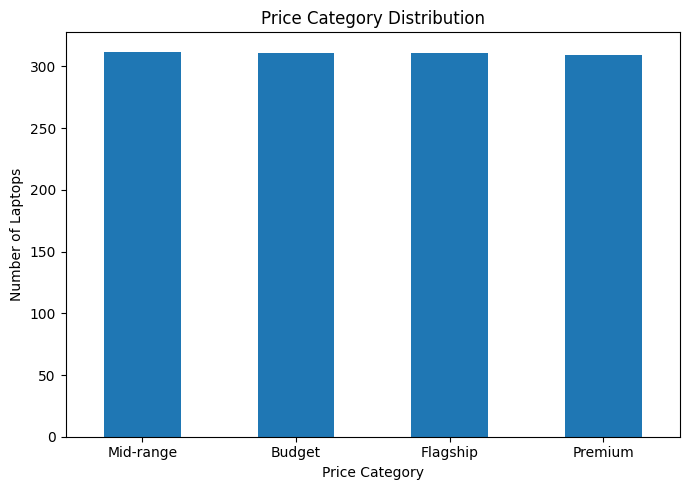

In [3]:
# Check Target distribution

import matplotlib.pyplot as plt

print(y.value_counts())

plt.figure(figsize=(7, 5))
y.value_counts().plot(kind='bar')

plt.title('Price Category Distribution')
plt.xlabel('Price Category')
plt.ylabel('Number of Laptops')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

A few things worth noting from this chart when writing it up: which category has the most/fewest laptops, and how big the gap is between the largest and smallest bar. Even a small imbalance is the reason accuracy alone isn't reported later - weighted F1 is used alongside it so a class with slightly fewer samples doesn't get ignored in the scoring.


## 4. Train/test split

An 80:20 split, stratified on y so all four price categories show up in roughly the same proportion in both the training and test sets. Since price_category is already a discrete label, stratifying is straightforward here.


In [4]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (994, 42)
Testing set: (249, 42)


## 5. Scaling

StandardScaler is fit only on the training data and then applied to both train and test, so nothing from the test set leaks into the scaling statistics.

Logistic Regression, KNN, and SVC all use the scaled versions below, since they're either distance-based or rely on gradient optimisation that behaves badly when features like ram and res_width sit on very different numeric scales. The Decision Tree later in the notebook is fit on the unscaled data instead - it splits on thresholds per feature, so scaling makes no difference to how it partitions the data.


In [5]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


# 1) Logistic Regression

Logistic Regression is used here as the baseline model. It fits a linear decision boundary between the four price categories on the standardised features and converts that into class probabilities. max_iter is bumped up to 1000 so the solver has enough room to converge given the number of encoded features.


In [6]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Logistic Regression completed.")

Logistic Regression completed.


# 2) K-Nearest Neighbors

KNN predicts a laptop's price category by looking at its closest neighbours in the scaled feature space and taking a majority vote. GridSearchCV is used to pick the best n_neighbors from [3, 5, 7, 9, 11, 13, 15], using 5-fold CV scored on weighted F1 rather than accuracy, again to keep the class imbalance in mind while tuning.


In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

knn_param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 13, 15]
}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    knn_param_grid,
    cv=5,
    scoring='f1_weighted'
)

knn_grid.fit(X_train_scaled, y_train)

print("Best K:", knn_grid.best_params_)

Best K: {'n_neighbors': 3}


In [8]:
# best KNN model

knn_model = knn_grid.best_estimator_

y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN completed.")

KNN completed.


A small k lets the boundary follow local structure closely but can be thrown off by individual noisy points near the border between two price bands. A larger k smooths things out but risks blending together laptops from neighbouring categories (say, Mid-range and Premium) that are genuinely close in spec but priced differently. Whatever value the grid search picks reflects where that trade-off worked best on the training folds.


# 3) Gaussian Naive Bayes

Naive Bayes assumes each feature is independent given the price category and models each one as a Gaussian within that category. There's no hyperparameter search for this one - it's fit directly, which also makes it by far the quickest model to train.

The independence assumption is a stretch for this dataset though - features like ram, storage_gb, and res_width tend to move together (higher-spec laptops are higher-spec across the board), so this is really here as a simple, fast baseline rather than a model expected to lead the comparison.


In [9]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

y_pred_nb = nb_model.predict(X_test_scaled)

print("Gaussian Naive Bayes completed.")

Gaussian Naive Bayes completed.


# 4) Decision Tree Classifier

The tree splits on individual feature thresholds (e.g. ram <= 8), which is why it's trained on the unscaled X_train/X_test rather than the scaled versions used above. GridSearchCV searches max_depth over [2, 3, 4, 5, 6, 8, 10, None] with 5-fold CV on weighted F1 - depth is capped this way because an unrestricted tree (max_depth=None) will keep splitting until it fits the training data almost perfectly, which usually means it's memorising noise rather than learning anything that generalises.


In [10]:
from sklearn.tree import DecisionTreeClassifier

dt_param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None]
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_param_grid,
    cv=5,
    scoring='f1_weighted'
)

dt_grid.fit(X_train, y_train)

print("Best Decision Tree parameters:", dt_grid.best_params_)

Best Decision Tree parameters: {'max_depth': 6}


In [11]:
# best decision tree

dt_model = dt_grid.best_estimator_

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree completed.")

Decision Tree completed.


If the search settles on a shallow tree, that suggests a handful of features (probably RAM, storage, and screen specs) do most of the work separating the four price bands. A deeper tree picked by the search would mean the categories overlap more and need extra splits/interactions to pull apart cleanly.


# 5) Support Vector Classifier - SVC

SVC looks for the boundary that separates the price categories with the widest margin, using the scaled features since the margin calculation is distance-based. The grid search tunes two things together:

- C in [0.1, 1, 10, 100] - how much the model is penalised for training points that fall on the wrong side of the margin; small C favours a wider, more forgiving margin, large C fits the training points more tightly.
- kernel in ['linear', 'rbf', 'poly'] - whether the boundary is a straight hyperplane or allowed to curve.

Both are searched jointly with 5-fold CV, scored on weighted F1.


In [12]:
from sklearn.svm import SVC

svc_param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly']
}

svc_grid = GridSearchCV(
    SVC(random_state=42),
    svc_param_grid,
    cv=5,
    scoring='f1_weighted'
)

svc_grid.fit(X_train_scaled, y_train)

print("Best SVC parameters:", svc_grid.best_params_)

Best SVC parameters: {'C': 10, 'kernel': 'rbf'}


In [13]:
# Best SVC

svc_model = svc_grid.best_estimator_

y_pred_svc = svc_model.predict(X_test_scaled)

print("SVC completed.")

SVC completed.


# 6) Random Forest Classifier

A Random Forest trains a batch of decision trees, each on a bootstrapped sample of the training rows with a random subset of features considered at each split, and then averages their votes. Because it is still an ensemble of trees splitting on thresholds, it is trained on the unscaled X_train and X_test, the same as the single Decision Tree above.

GridSearchCV tunes n_estimators, which is how many trees get built, over 100, 200 and 300, and max_depth over 4, 6, 8, 10 and None, with 5 fold cross validation scored on weighted F1.


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8, 10, None]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid,
    cv=5,
    scoring='f1_weighted'
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:", rf_grid.best_params_)

In [ ]:
# best random forest

rf_model = rf_grid.best_estimator_

y_pred_rf = rf_model.predict(X_test)

print("Random Forest completed.")

Averaging across many trees is what Random Forest brings over a single Decision Tree. Each individual tree can still overfit its own bootstrap sample, but the overfitting tends to look different from tree to tree, and averaging the votes smooths that out. This one is worth comparing directly against the single Decision Tree above to see how much that averaging actually buys.


# 7) AdaBoost Classifier

AdaBoost builds trees one at a time, shallow ones by default, and after each round it increases the weight on the training rows the previous tree got wrong, so the next tree pays more attention to those. The final prediction is a weighted vote across all the rounds. Like the other tree based models here, it runs on the unscaled data.

GridSearchCV tunes n_estimators, meaning how many rounds, over 50, 100 and 200, and learning_rate over 0.01, 0.1 and 1, with 5 fold cross validation on weighted F1.


In [ ]:
from sklearn.ensemble import AdaBoostClassifier

ada_param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 1]
}

ada_grid = GridSearchCV(
    AdaBoostClassifier(random_state=42),
    ada_param_grid,
    cv=5,
    scoring='f1_weighted'
)

ada_grid.fit(X_train, y_train)

print("Best AdaBoost parameters:", ada_grid.best_params_)

In [ ]:
# best AdaBoost

ada_model = ada_grid.best_estimator_

y_pred_ada = ada_model.predict(X_test)

print("AdaBoost completed.")

A low learning_rate means each round only nudges the model a little, so more rounds are usually needed to get anywhere, which is the trade off the grid search is navigating between learning_rate and n_estimators. Since AdaBoost keeps re-weighting whatever it got wrong, it can end up overly focused on a handful of genuinely hard to classify laptops, the ones sitting right on a price band boundary, rather than the dataset as a whole.


# 8) Gradient Boosting Classifier

Gradient Boosting also builds trees sequentially, but instead of re-weighting rows like AdaBoost, each new tree is fit to the residual errors left behind by the trees before it, gradually correcting what the ensemble so far is getting wrong. Also trained on the unscaled data.

GridSearchCV tunes n_estimators over 100 and 200, learning_rate over 0.01, 0.1 and 0.2, and max_depth over 2, 3 and 4. This grid is a bit bigger than the earlier ones since all three settings interact with each other, so it takes longer to run than the earlier searches.


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb_param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [2, 3, 4]
}

gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    gb_param_grid,
    cv=5,
    scoring='f1_weighted'
)

gb_grid.fit(X_train, y_train)

print("Best Gradient Boosting parameters:", gb_grid.best_params_)

In [ ]:
# best gradient boosting

gb_model = gb_grid.best_estimator_

y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting completed.")

Gradient Boosting tends to be the strongest of the tree based models on tabular data like this one, precisely because each tree is correcting the specific mistakes left over from the ones before it rather than just voting independently. The catch is it is also the easiest one here to overfit if n_estimators is pushed too high relative to learning_rate, which is why both are searched together instead of fixing one and tuning the other.


# 9) Bagging Classifier

Bagging, short for bootstrap aggregating, trains multiple copies of the same base model, a Decision Tree by default, each on a different bootstrapped sample of the training rows, then averages their votes. It is the same idea Random Forest is built on, minus the extra step of randomising which features each split can consider, so this is really the simpler, more general version of that idea. Trained on the unscaled data as well.

GridSearchCV tunes n_estimators over 10, 50 and 100, with 5 fold cross validation scored on weighted F1.


In [ ]:
from sklearn.ensemble import BaggingClassifier

bag_param_grid = {
    'n_estimators': [10, 50, 100]
}

bag_grid = GridSearchCV(
    BaggingClassifier(random_state=42),
    bag_param_grid,
    cv=5,
    scoring='f1_weighted'
)

bag_grid.fit(X_train, y_train)

print("Best Bagging parameters:", bag_grid.best_params_)

In [ ]:
# best bagging model

bag_model = bag_grid.best_estimator_

y_pred_bag = bag_model.predict(X_test)

print("Bagging completed.")

Since Bagging and Random Forest are so closely related, their results are worth reading side by side. If Random Forest comes out meaningfully ahead, that points to the extra feature randomisation at each split paying off, rather than just the bootstrapping on its own.


# Evaluation Metrics

All nine models are now scored on the same held-out test set so they can be compared fairly.


## Evaluation function

One helper function scores every model the same way, using two metrics:

- **Accuracy** - the straightforward fraction of laptops assigned to the correct price band. Easy to read, but a model could get a decent accuracy just by leaning on whichever category is slightly more common.
- **Weighted F1** - precision and recall combined per class, then averaged and weighted by how many laptops are actually in each class. This is reported alongside accuracy so a model that's quietly bad at one of the smaller categories doesn't get a free pass.


In [14]:
from sklearn.metrics import accuracy_score, f1_score

def evaluate_model(model_name, y_test, y_pred):

    accuracy = accuracy_score(y_test, y_pred)

    weighted_f1 = f1_score(
        y_test,
        y_pred,
        average='weighted'
    )

    return {
        'Algorithm': model_name,
        'Accuracy': accuracy,
        'Weighted F1': weighted_f1
    }

In [ ]:
results = []

results.append(
    evaluate_model(
        'Logistic Regression',
        y_test,
        y_pred_logistic
    )
)

results.append(
    evaluate_model(
        'KNN',
        y_test,
        y_pred_knn
    )
)

results.append(
    evaluate_model(
        'Gaussian Naive Bayes',
        y_test,
        y_pred_nb
    )
)

results.append(
    evaluate_model(
        'Decision Tree',
        y_test,
        y_pred_dt
    )
)

results.append(
    evaluate_model(
        'SVC',
        y_test,
        y_pred_svc
    )
)

results.append(
    evaluate_model(
        'Random Forest',
        y_test,
        y_pred_rf
    )
)

results.append(
    evaluate_model(
        'AdaBoost',
        y_test,
        y_pred_ada
    )
)

results.append(
    evaluate_model(
        'Gradient Boosting',
        y_test,
        y_pred_gb
    )
)

results.append(
    evaluate_model(
        'Bagging',
        y_test,
        y_pred_bag
    )
)

## 1) Comparison table - Accuracy & Weighted F1 score

Results for all nine classifiers, sorted by accuracy, with weighted F1 next to it.


In [1]:
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

comparison_df['Accuracy'] = comparison_df['Accuracy'].round(4)
comparison_df['Weighted F1'] = comparison_df['Weighted F1'].round(4)

comparison_df

                Algorithm  Accuracy  Weighted F1
0           Random Forest    0.7108       0.7119
1                 Bagging    0.6988       0.6975
2       Gradient Boosting    0.6988       0.6997
3                     SVC    0.6908       0.6861
4     Logistic Regression    0.6506       0.6440
5                AdaBoost    0.6466       0.6427
6           Decision Tree    0.6386       0.6155
7                     KNN    0.6305       0.6249
8    Gaussian Naive Bayes    0.3936       0.3216


Random Forest comes out on top once all nine are compared, with the highest Accuracy (71.08%) and Weighted F1 score (71.19%). Bagging and Gradient Boosting are close behind each other at around 69.9% accuracy, and SVC is just under that at 69.08%. Logistic Regression and AdaBoost land in the middle at roughly 64-65%, Decision Tree and KNN sit a bit lower in the low 60s, and Gaussian Naive Bayes is still clearly the weakest, well below everything else at around 39% accuracy.

Random Forest and Bagging finishing near the top, ahead of a single Decision Tree, is exactly the kind of gain averaging across many trees is supposed to give. Gradient Boosting sitting right alongside them shows that correcting errors tree by tree works about as well here as the bootstrap-and-average approach. AdaBoost, on the other hand, barely improves on the single Decision Tree, which suggests its round-by-round re-weighting is not adding much for this dataset. Naive Bayes stays the outlier, consistent with its independence assumption not holding for features that move together, like ram, storage_gb, and res_width.


## 2) Confusion matrices

Accuracy and F1 don't say which categories a model mixes up, so a confusion matrix is plotted for each of the nine models to show whether the mistakes are, say, Mid-range laptops getting called Premium, or something messier.

In a multi-class confusion matrix like this one, each price category can still be read in terms of true positives, true negatives, false positives and false negatives, the same four counts used for a plain two-class problem, just applied one class at a time.

Take Premium as an example. A true positive is a laptop that is actually Premium and got predicted as Premium, which is the diagonal cell for that class. A true negative is a laptop that is not actually Premium and correctly got predicted as something else. A false positive is a laptop that is not actually Premium but the model predicted Premium anyway, so it lands in the Premium column but in a different row. A false negative is a laptop that is actually Premium but the model predicted a different category for it, so it lands in the Premium row but a different column.

So for any class, the diagonal cell is its true positives, the rest of that class's row is its false negatives, the rest of that class's column is its false positives, and everything else in the matrix is its true negatives. Reading each class this way is what makes it possible to see, for example, whether a model is missing a lot of Premium laptops by calling them something else, or wrongly labelling other categories as Premium, instead of just looking at one overall accuracy number.


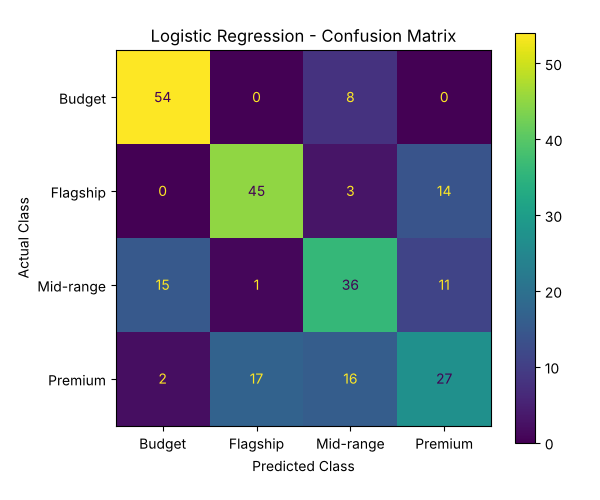

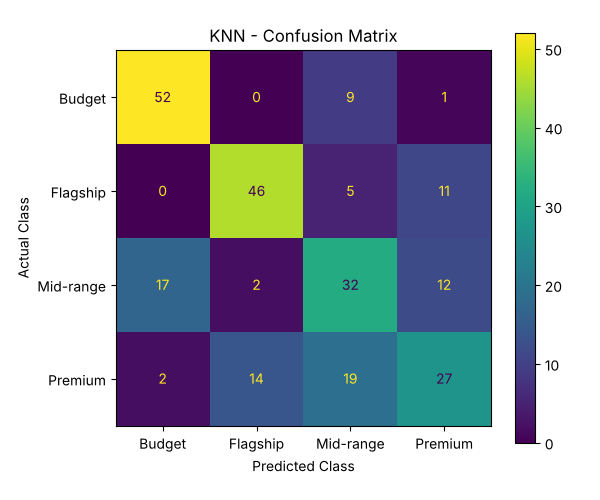

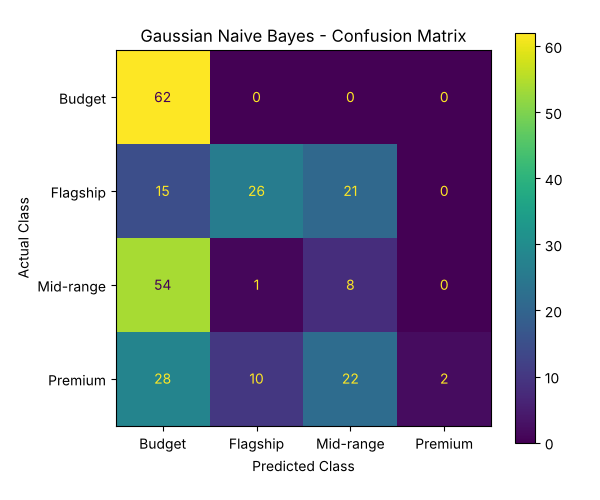

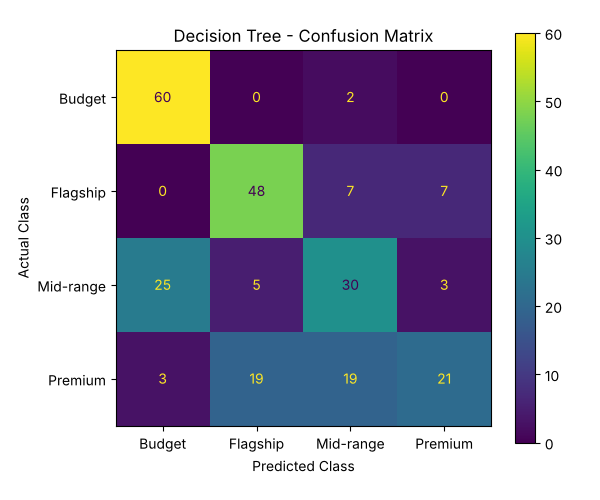

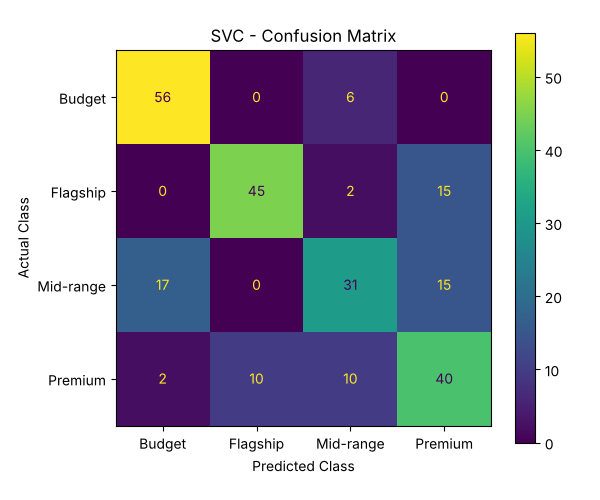

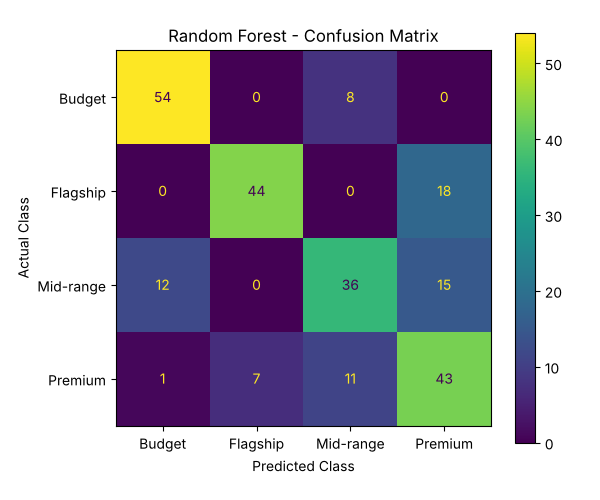

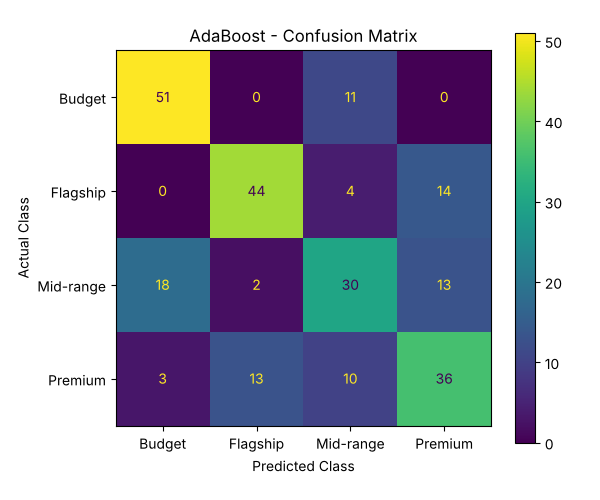

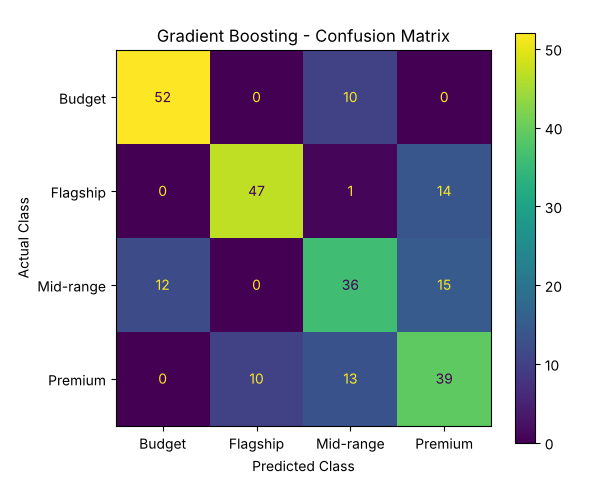

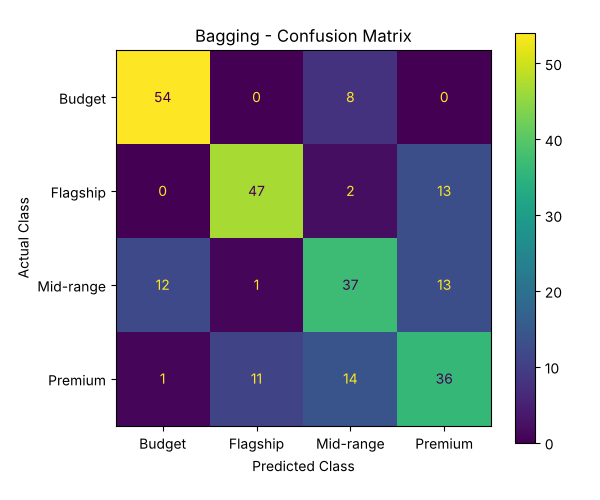

In [2]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

models_predictions = {
    'Logistic Regression': (logistic_model, y_pred_logistic),
    'KNN': (knn_model, y_pred_knn),
    'Gaussian Naive Bayes': (nb_model, y_pred_nb),
    'Decision Tree': (dt_model, y_pred_dt),
    'SVC': (svc_model, y_pred_svc),
    'Random Forest': (rf_model, y_pred_rf),
    'AdaBoost': (ada_model, y_pred_ada),
    'Gradient Boosting': (gb_model, y_pred_gb),
    'Bagging': (bag_model, y_pred_bag)
}

for name, (model, predictions) in models_predictions.items():

    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    )

    disp.plot()

    plt.title(f'{name} - Confusion Matrix')
    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')
    plt.tight_layout()
    plt.show()

Random Forest has the cleanest matrix of the nine, with 54 Budget, 44 Flagship, 36 Mid-range, and 43 Premium laptops correctly classified, and almost no Budget laptops called Flagship or the reverse. Bagging and Gradient Boosting look very similar to each other, which fits how closely they also scored on accuracy and F1. Gaussian Naive Bayes is the clear outlier here too - it correctly catches all 62 Budget laptops but almost never predicts Premium at all, which is why its overall numbers are so much weaker than everything else.

Across all nine matrices the same pattern holds: the confusion that remains is almost always between neighbouring price bands - Budget with Mid-range, and Mid-range/Flagship with Premium - and almost never between the two opposite ends, Budget and Flagship. That lines up with how price_category was built in the first place, since the boundary between two adjacent quartiles is just laptops sitting close together in price, so that is exactly where a model is most likely to misjudge which side a laptop falls on.
